## CORDIC Testbench


This notebook is to test the implementation of a CORDIC running on the programmable logic. The CORDIC is used to convert cartesian to polar coordinates. The output is compared with a Python calculation of the coordinate transform. It takes in x and y and gives out r and theta where r is the radius and theta is the angle.

In [1]:
from pynq import Overlay
from pynq import MMIO
import numpy as np
import struct
import binascii
import cmath
import random
import matplotlib.pyplot as plt

NUM_SAMPLES = 1000

In [2]:
ol=Overlay('./cordic.bit') #Change name of bitstream as required

In [3]:
# AUP-ZU3: take the base address and register offsets from the .hwh instead of hard-coding them
cordic_info = ol.ip_dict['cordiccart2pol_0']
cordic_ip = MMIO(cordic_info['phys_addr'], 0x10000)
print("Base address:", hex(cordic_info['phys_addr']))
for name, reg in cordic_info['registers'].items():
    print(f"  {name:12s} {hex(reg['address_offset'])}")

# Register offsets (Vitis HLS 2024.2, see xcordiccart2pol_hw.h)
CTRL_OFFSET  = 0x00   # bit 0 = ap_start, bit 1 = ap_done (clear on read)
X_OFFSET     = 0x10
Y_OFFSET     = 0x18
R_OFFSET     = 0x20
THETA_OFFSET = 0x30
AP_DONE_BIT  = 0x2

Base address: 0x80000000
  CTRL         0x0
  GIER         0x4
  IP_IER       0x8
  IP_ISR       0xc
  x            0x10
  y            0x18
  r            0x20
  r_ctrl       0x24
  theta        0x30
  theta_ctrl   0x34


In [4]:
r_error=np.zeros(NUM_SAMPLES)
theta_error=np.zeros(NUM_SAMPLES)
ind=np.arange(NUM_SAMPLES)
r_rmse=np.zeros(NUM_SAMPLES)
theta_rmse=np.zeros(NUM_SAMPLES)

In [5]:
# make sure rounding from 64 bit double introduces no error to 32 bit float
def float_to_bits(value):
    return struct.unpack('<I', struct.pack('<f', value))[0]

def bits_to_float(bits):
    return struct.unpack('<f', struct.pack('<I', bits))[0]

for i in range(NUM_SAMPLES):
    #Generating random inputs
    x=random.uniform(-1,1)
    y=random.uniform(-1,1)
    
    #Computing golden output
    cn=complex(x,y)
    cn=cmath.polar(cn)
    
    #Writing values to the FPGA (as raw float bits)
    cordic_ip.write(X_OFFSET, float_to_bits(x))
    cordic_ip.write(Y_OFFSET, float_to_bits(y))
    
    #Starting the IP and waiting until it is done.
    #Without this wait, r can be read before the result is written (stale value from the previous sample).
    cordic_ip.write(CTRL_OFFSET, 1)
    for _ in range(100000):
        if cordic_ip.read(CTRL_OFFSET) & AP_DONE_BIT:
            break
    else:
        raise TimeoutError("CORDIC IP did not finish (check bitstream / offsets)")
    
    #Reading from IP and converting to float
    r = bits_to_float(cordic_ip.read(R_OFFSET))
    theta = bits_to_float(cordic_ip.read(THETA_OFFSET))
        
    #Comparing with golden output    
    r_error[i] = abs(r-cn[0])
    theta_error[i] = abs(theta-cn[1])

## Verifying Functionality

In [6]:
sum_sq_r=0
sum_sq_theta=0
for i in range(NUM_SAMPLES):
    sum_sq_r =sum_sq_r+(r_error[i]*r_error[i])
    r_rmse = np.sqrt(sum_sq_r / (i+1))
    sum_sq_theta =sum_sq_theta+(theta_error[i]*theta_error[i])
    theta_rmse = np.sqrt(sum_sq_theta / (i+1))
print("Radius RMSE: ", r_rmse, "Theta RMSE:", theta_rmse)    
if r_rmse<0.001 and theta_rmse<0.001:
    print("PASS")
else:
    print("FAIL")

Radius RMSE:  2.5802445321357148e-08 Theta RMSE: 1.1228197399624691e-06
PASS


## Displaying Errors

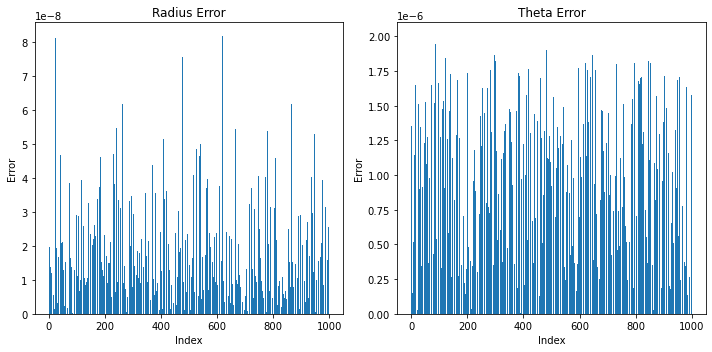

In [7]:
plt.figure(figsize=(10, 5))
plt.subplot(1,2,1)
plt.bar(ind,r_error)
plt.title("Radius Error")
plt.xlabel("Index")
plt.ylabel("Error")
#plt.xticks(ind)
plt.tight_layout()

plt.subplot(1,2,2)
plt.bar(ind,theta_error)
plt.title("Theta Error")
plt.xlabel("Index")
plt.ylabel("Error")
#plt.xticks(ind)
plt.tight_layout()